# Segmentación de clientes con RFM y K-means

**Pregunta de negocio:** no todos los clientes valen lo mismo ni necesitan el mismo trato. ¿Cómo agruparlos para diseñar una estrategia comercial distinta para cada grupo?

**Datos:** [Online Retail II (UCI)](https://archive.ics.uci.edu/dataset/502/online+retail+ii), transacciones 2009–2011 de un comercio en línea del Reino Unido. Licencia CC BY 4.0.

**Contenido**
1. Carga y limpieza
2. Cálculo de RFM
3. Segmentos por reglas RFM
4. Segmentos con K-means
5. Estrategia por segmento y exportación

In [1]:
import io
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

PALETA = ["#6B2D8C", "#7A1F3D", "#B23A6A", "#D9C2E8", "#3E2447", "#E9A6C1"]
sns.set_theme(style="whitegrid", palette=PALETA)
RANDOM_STATE = 42

DATA_DIR = Path("data/raw")
OUT_DIR = Path("outputs")
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

## 1. Carga y limpieza
El Excel original tiene dos hojas (2009–2010 y 2010–2011) y más de un millón de filas. La primera lectura tarda unos minutos; después se guarda una copia en CSV para cargar rápido.

In [2]:
URL = "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"
XLSX = DATA_DIR / "online_retail_II.xlsx"
CACHE = DATA_DIR / "online_retail_II.csv"


def cargar_datos():
    if CACHE.exists():
        return pd.read_csv(CACHE, dtype={"Invoice": str, "StockCode": str}, parse_dates=["InvoiceDate"])
    if not XLSX.exists():
        print("Descargando Online Retail II desde UCI...")
        with urllib.request.urlopen(URL) as r:
            z = zipfile.ZipFile(io.BytesIO(r.read()))
        miembro = next(n for n in z.namelist() if n.endswith(".xlsx"))
        XLSX.write_bytes(z.read(miembro))
    print("Leyendo Excel (puede tardar unos minutos)...")
    hojas = pd.read_excel(XLSX, sheet_name=None, dtype={"Invoice": str, "StockCode": str})
    datos = pd.concat(hojas.values(), ignore_index=True)
    datos.to_csv(CACHE, index=False)
    return datos


df = cargar_datos()
print(df.shape)
df.head()

Descargando Online Retail II desde UCI...
Leyendo Excel (puede tardar unos minutos)...
(1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [3]:
filas_iniciales = len(df)
df = df.rename(columns={"Customer ID": "cliente"})
df = df.dropna(subset=["cliente"])
df = df[~df["Invoice"].astype(str).str.startswith("C")]   # facturas canceladas
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]
df = df.drop_duplicates()
df["cliente"] = df["cliente"].astype(int)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["ingreso"] = df["Quantity"] * df["Price"]

print(f"Filas: {filas_iniciales:,} → {len(df):,} tras la limpieza")
print(f"Clientes: {df['cliente'].nunique():,}")
print(f"Periodo: {df['InvoiceDate'].min():%Y-%m-%d} a {df['InvoiceDate'].max():%Y-%m-%d}")

Filas: 1,067,371 → 779,425 tras la limpieza
Clientes: 5,878
Periodo: 2009-12-01 a 2011-12-09


## 2. Cálculo de RFM
- **Recencia:** días desde la última compra (menos es mejor)
- **Frecuencia:** número de facturas distintas
- **Monto:** ingreso total generado

In [4]:
fecha_corte = df["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = df.groupby("cliente").agg(
    recencia=("InvoiceDate", lambda s: (fecha_corte - s.max()).days),
    frecuencia=("Invoice", "nunique"),
    monto=("ingreso", "sum"),
)
rfm.describe().round(1)

C:\Users\VICTUS\AppData\Local\Temp\ipykernel_12212\3694242266.py:1: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  fecha_corte = df["InvoiceDate"].max() + pd.Timedelta(days=1)


,recencia,frecuencia,monto
count,5878.0,5878.0,5878.0
mean,201.3,6.3,2955.9
std,209.3,13.0,14440.9
min,1.0,1.0,3.0
25%,26.0,1.0,342.3
50%,96.0,3.0,867.7
75%,380.0,7.0,2248.3
max,739.0,398.0,580987.0


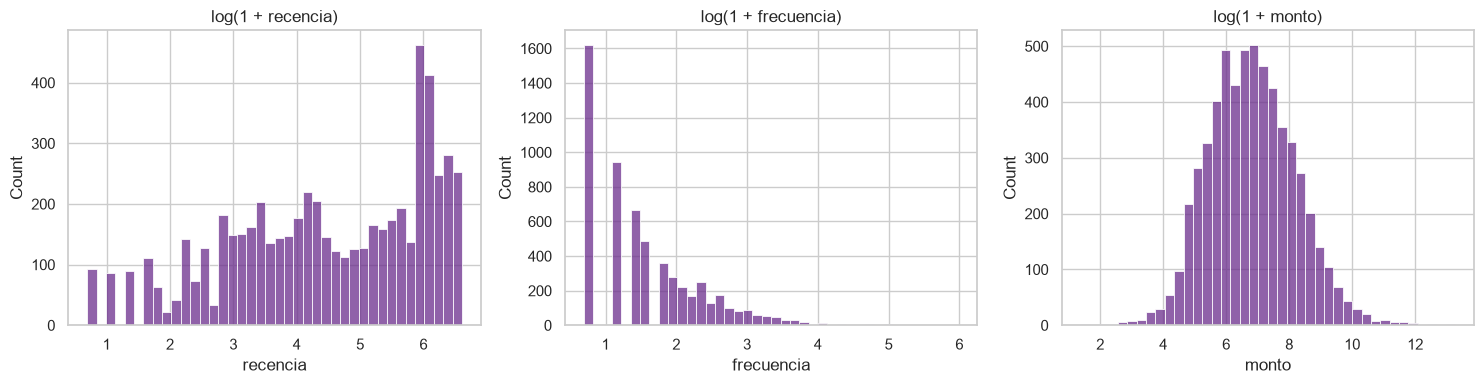

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["recencia", "frecuencia", "monto"]):
    sns.histplot(np.log1p(rfm[col]), bins=40, ax=ax, color=PALETA[0])
    ax.set_title(f"log(1 + {col})")
plt.tight_layout()
plt.show()

## 3. Segmentos por reglas RFM
Puntuamos recencia y frecuencia del 1 al 5 (quintiles) y asignamos segmentos con reglas fáciles de explicar al equipo comercial.

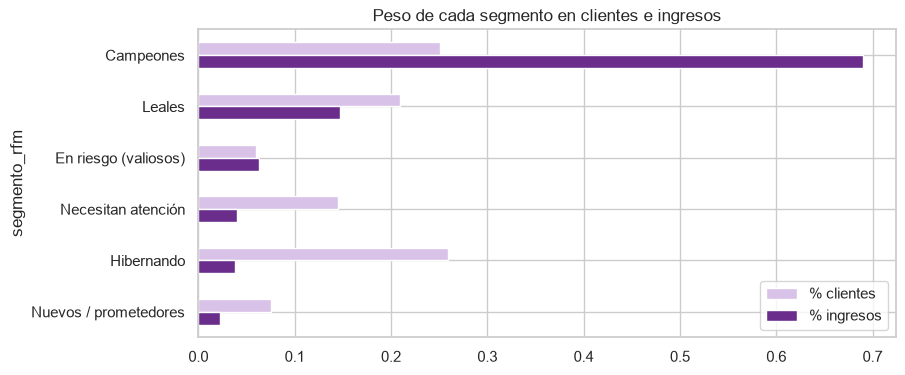

,clientes,recencia_media,frecuencia_media,monto_total,% clientes,% ingresos
segmento_rfm,,,,,,
Campeones,1473,20.13,15.69,11983421.68,0.25,0.69
Leales,1229,78.34,5.45,2549954.54,0.21,0.15
En riesgo (valiosos),354,343.77,7.57,1091694.54,0.06,0.06
Necesitan atención,855,261.31,2.25,702450.56,0.15,0.04
Hibernando,1526,458.75,1.25,655444.68,0.26,0.04
Nuevos / prometedores,441,27.97,1.46,391838.26,0.08,0.02


In [6]:
rfm["R"] = pd.qcut(rfm["recencia"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["frecuencia"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["monto"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)


def segmento_rfm(r, f):
    if r >= 4 and f >= 4:
        return "Campeones"
    if r >= 3 and f >= 3:
        return "Leales"
    if r >= 4 and f <= 2:
        return "Nuevos / prometedores"
    if r <= 2 and f >= 4:
        return "En riesgo (valiosos)"
    if r <= 2 and f <= 2:
        return "Hibernando"
    return "Necesitan atención"


rfm["segmento_rfm"] = [segmento_rfm(r, f) for r, f in zip(rfm["R"], rfm["F"])]

resumen_rfm = rfm.groupby("segmento_rfm").agg(
    clientes=("monto", "size"),
    recencia_media=("recencia", "mean"),
    frecuencia_media=("frecuencia", "mean"),
    monto_total=("monto", "sum"),
)
resumen_rfm["% clientes"] = resumen_rfm["clientes"] / resumen_rfm["clientes"].sum()
resumen_rfm["% ingresos"] = resumen_rfm["monto_total"] / resumen_rfm["monto_total"].sum()
resumen_rfm = resumen_rfm.sort_values("% ingresos", ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
resumen_rfm[["% clientes", "% ingresos"]].plot.barh(ax=ax, color=[PALETA[3], PALETA[0]])
ax.invert_yaxis()
ax.set_title("Peso de cada segmento en clientes e ingresos")
plt.show()
resumen_rfm.round(2)

## 4. Segmentos con K-means
Aplicamos logaritmo (las variables están muy sesgadas), estandarizamos y elegimos el número de grupos con el método del codo y el coeficiente de silueta.

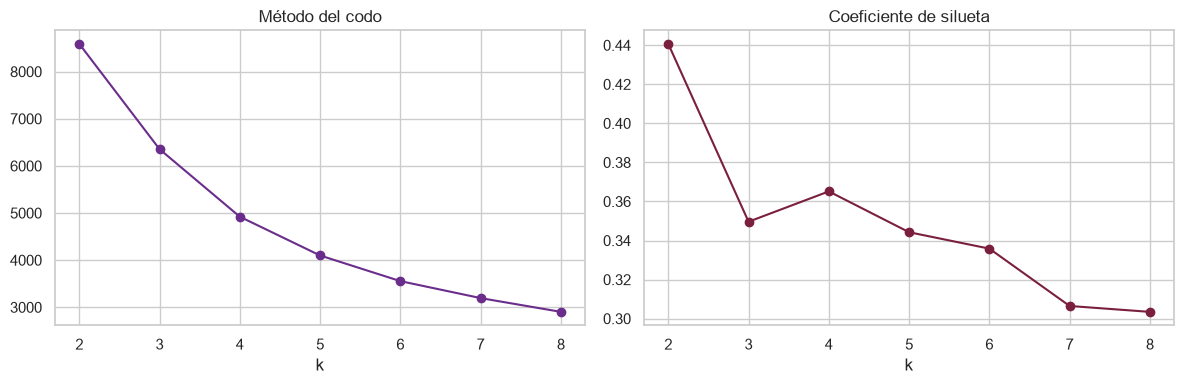

In [7]:
X = StandardScaler().fit_transform(np.log1p(rfm[["recencia", "frecuencia", "monto"]]))

ks, inercias, siluetas = range(2, 9), [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X, km.labels_, sample_size=min(5000, len(X)), random_state=RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(ks), inercias, marker="o", color=PALETA[0])
axes[0].set_title("Método del codo")
axes[0].set_xlabel("k")
axes[1].plot(list(ks), siluetas, marker="o", color=PALETA[1])
axes[1].set_title("Coeficiente de silueta")
axes[1].set_xlabel("k")
plt.tight_layout()
plt.show()

In [8]:
K = 4  # ajusta según los gráficos anteriores
km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X)
rfm["cluster"] = km.labels_

perfil = rfm.groupby("cluster").agg(
    clientes=("monto", "size"),
    recencia_media=("recencia", "mean"),
    frecuencia_media=("frecuencia", "mean"),
    monto_medio=("monto", "mean"),
    monto_total=("monto", "sum"),
)
# Ordenamos los clusters de mayor a menor valor (alta frecuencia y monto, baja recencia)
z = (perfil[["recencia_media", "frecuencia_media", "monto_medio"]] - perfil[["recencia_media", "frecuencia_media", "monto_medio"]].mean()) / perfil[["recencia_media", "frecuencia_media", "monto_medio"]].std()
perfil["valor"] = -z["recencia_media"] + z["frecuencia_media"] + z["monto_medio"]
perfil = perfil.sort_values("valor", ascending=False)

NOMBRES = ["Alto valor", "En crecimiento", "Ocasionales", "Perdidos"]
nombres = {c: (NOMBRES[i] if K == 4 else f"Grupo {i + 1}") for i, c in enumerate(perfil.index)}
perfil["nombre"] = perfil.index.map(nombres)
rfm["segmento_kmeans"] = rfm["cluster"].map(nombres)
perfil["% ingresos"] = perfil["monto_total"] / perfil["monto_total"].sum()
perfil.set_index("nombre").drop(columns="valor").round(1)

,clientes,recencia_media,frecuencia_media,monto_medio,monto_total,% ingresos
nombre,,,,,,
Alto valor,1196,27.7,19.3,10731.2,12834470.9,0.7
En crecimiento,1250,28.3,3.1,857.5,1071864.3,0.1
Ocasionales,1459,230.1,5.1,1948.5,2842867.2,0.2
Perdidos,1973,394.9,1.4,317.1,625601.8,0.0


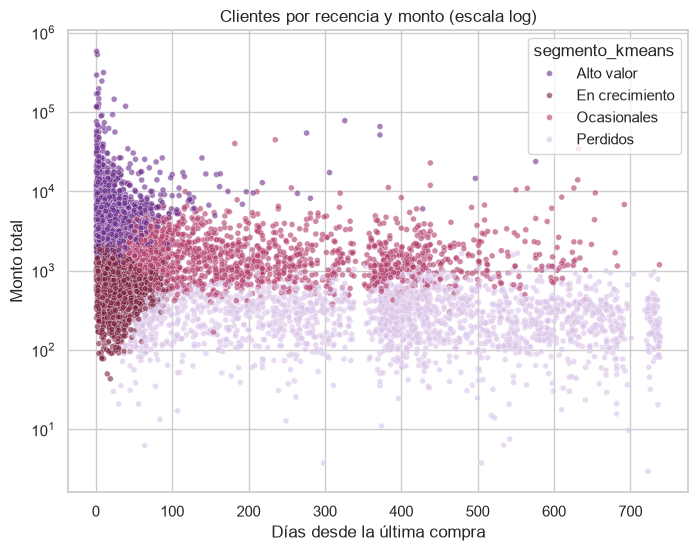

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=rfm, x="recencia", y="monto", hue="segmento_kmeans",
                hue_order=[nombres[c] for c in perfil.index], alpha=0.6, s=18, ax=ax, palette=PALETA[:K])
ax.set_yscale("log")
ax.set_title("Clientes por recencia y monto (escala log)")
ax.set_xlabel("Días desde la última compra")
ax.set_ylabel("Monto total")
plt.show()

## 5. Estrategia por segmento

In [10]:
ESTRATEGIA = {
    "Campeones": "Programa de fidelidad, acceso anticipado a novedades, pedir referidos.",
    "Leales": "Venta cruzada y beneficios por volumen.",
    "Nuevos / prometedores": "Secuencia de bienvenida y segunda compra con incentivo.",
    "Necesitan atención": "Ofertas personalizadas según historial de compra.",
    "En riesgo (valiosos)": "Contacto directo y oferta de recuperación antes de que se pierdan.",
    "Hibernando": "Campaña de reactivación de bajo costo; si no responden, reducir inversión.",
}
estrategia = resumen_rfm[["clientes", "% ingresos"]].copy()
estrategia["acción sugerida"] = estrategia.index.map(ESTRATEGIA)
estrategia.style.format({"% ingresos": "{:.1%}"})

,clientes,% ingresos,acción sugerida
segmento_rfm,,,
Campeones,1473,69.0%,"Programa de fidelidad, acceso anticipado a novedades, pedir referidos."
Leales,1229,14.7%,Venta cruzada y beneficios por volumen.
En riesgo (valiosos),354,6.3%,Contacto directo y oferta de recuperación antes de que se pierdan.
Necesitan atención,855,4.0%,Ofertas personalizadas según historial de compra.
Hibernando,1526,3.8%,"Campaña de reactivación de bajo costo; si no responden, reducir inversión."
Nuevos / prometedores,441,2.3%,Secuencia de bienvenida y segunda compra con incentivo.


In [11]:
rfm.reset_index().to_csv(OUT_DIR / "clientes_segmentados.csv", index=False)
print("Exportado:", OUT_DIR / "clientes_segmentados.csv")

Exportado: outputs\clientes_segmentados.csv


## Conclusiones
- Una minoría de clientes (Campeones y Leales) concentra la mayor parte de los ingresos: protegerlos es prioritario.
- El segmento "En riesgo (valiosos)" compraba mucho pero dejó de hacerlo; es la mejor oportunidad de recuperación.
- K-means confirma una estructura similar a la de las reglas RFM, con grupos que el negocio puede entender y accionar.